# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

# Aula 15 - Laboratório 6 - Detector de atividade vocal (VAD) através da taxa de cruzamento de zeros e do achatamento espectral

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook.

In [1]:
# @title
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
import math
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

In [2]:
import os, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/Mathcd/2026-3-Processamento-de-Voz-e-Audio/main/2-ExerciciosComputacionais/Audios/"

def caminho_audio(nome):
    """Usa o áudio local se existir; senão baixa do GitHub (ex.: no Colab)."""
    caminho = os.path.join("Audios", nome)
    if not os.path.exists(caminho):
        os.makedirs("Audios", exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + nome, caminho)
    return caminho

In [3]:
# @title
 #Plot frequency and phase response - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz(b,a=1,fs=44100):
    w,h = signal.freqz(b,a)
    h_dB = 20 * np.log10 (abs(h))
    plot(w/max(w)*fs/2,h_dB)
    ylabel('Amplitude')
    xlabel(r'Frequency [Hz]')
    title(r'Frequency response')
    plt.grid(True)

def zcr(signal):
    # Conta quantas vezes o sinal muda de sinal (positivo/negativo)
    crossings = np.sum(np.abs(np.diff(np.signbit(signal))))
    return crossings / len(signal)

def add_awgn_real(signal, target_snr_db):
    """
    Adiciona ruído AWGN a um sinal real com base na SNR desejada (em dB).
    """
    # 1. Calcular a potência do sinal
    signal_power = np.mean(signal ** 2)

    # 2. Converter SNR de dB para escala linear
    snr_linear = 10 ** (target_snr_db / 10)

    # 3. Calcular a potência do ruído necessária
    noise_power = signal_power / snr_linear

    # 4. O desvio padrão (sigma) do ruído é a raiz quadrada da sua potência
    # Para sinais reais: σ = sqrt(Psig / SNR)
    sigma = np.sqrt(noise_power)

    # 5. Gerar o ruído gaussiano (média 0, desvio padrão sigma)
    rng = np.random.default_rng()
    noise = rng.normal(loc=0.0, scale=sigma, size=signal.shape)

    # 6. Retornar o sinal com o ruído adicionado
    return signal + noise


Existem vários métodos que podem ser utilizados para a Detecção de Atividade Vocal (VAD, do inglês *Voice Activity Detection*). Na aula anterior, vimos dois métodos bastante simples que funcionam através da energia de um frame ou da amplitude máxima de um frame. Se a **Energia** do frame ou sua **Amplitude máxima** for maior do que um limiar, a janela é tida como contendo um sinal de voz. Caso contrário, é considerada como não contendo um sinal de voz.

No entanto, os métodos baseados em Energia ou em Amplitude são pouco robustos à ruído de fundo e os valores dos limiares ótimos podem variar consideravelmente de um sinal para outro.

Nesta aula iremos estudar outros dois atributos bastante utilizados em tarefas envolvendo o processamento de sinal de audio e voz e que podem ser utilizados para compor uma VAD. A **taxa de cruzamento de zero** (ZCR, do inglês *Zero Crossing Rate*) e o **achatamento espectral**, conhecido, em inglês, como *Spectral Flatness* (SF).

# Taxa de cruzamento de zeros

A ZCR é uma métrica bastante utilizada no processamento de sinais de áudio e voz e está bastante relacionada à frequência de um sinal que possui média nula. A ZCR busca, basicamente, contar a quantidade de vezes que o sinal do valor transiciona de um valor positivo para um valor negativo e vice-versa.

Desta forma, valores elevados de ZCR estão associados à ruído aleatório ou a sons do tipo não vozeados (conteúdo de alta frequência). Já valores mais baixos de ZCR estão associados à sons do tipo vozeados (conteúdo de baixa frequência).

A ZCR média de um sinal $x[n]$ pode ser calculada como sendo:
$$ ZCR = \frac{1}{N-1} \sum_{n=1}^{N-1} 0.5*|sgn(x[n])-sgn(x[n-1])|$$
onde $sgn()$ é a função sinal.

Observe que a ZCR média é uma medida que varia entre 0 e 1. 0 significa que não houve nenhuma transição do sinal no intervalo de tempo considerado e 1 significa que houve uma transição de sinal a cada amostra consecutiva.

# Achatamento espectral

O achatamento espectral é uma medida que busca quantificar o quão plano é o espectro de amplitude de um determinado sinal. Valores próximos de zero costumam estar relacionados com sons tonais, enquanto que valores próximos a 1 estão relacionados à ruído branco.

O SF é calculado como sendo a razão entre a média geométrica e a média aritmética da sua densidade espectral de potência:
$$SF = \frac{(\prod_{k=0}^{K-1}P[k])^{1/K}}{(\frac{1}{K}\sum_{k=0}^{K-1}P[k])},$$
onde $P[k]=\frac{1}{K}X^2[k]$, e $X[k]$ é a transformada discreta de Fourier do sinal $x[n]$.

# Parte 1: Reamostrando o sinal de áudio

Faça o download do arquivo "voz2.wav", disponível em: https://drive.google.com/file/d/1iZyHWB_xoLzfF8n7g79EZZCQK0okFDeP/view?usp=sharing

In [4]:
sr = 44100
audio_sample, fs = librosa.load(caminho_audio('matheus_celular.wav'), sr=sr) # 44100 corresponde à taxa de amostragem do sinal

In [5]:
Audio(data=audio_sample, rate=sr) # Reproduzindo o sinal de voz

In [6]:
fs = 8000
audio_resample = librosa.resample(audio_sample, orig_sr=sr, target_sr=fs)

In [7]:
Audio(data=audio_resample, rate=fs) # Reproduzindo o sinal de voz reamostrado

In [8]:
T = len(audio_resample) # Obtendo o número de amostras do sinal de voz
print(T)

171520


In [9]:
audio_resample = audio_resample - mean(audio_resample) # removendo a média do sinal, para que o sinal resultante tenha média nula

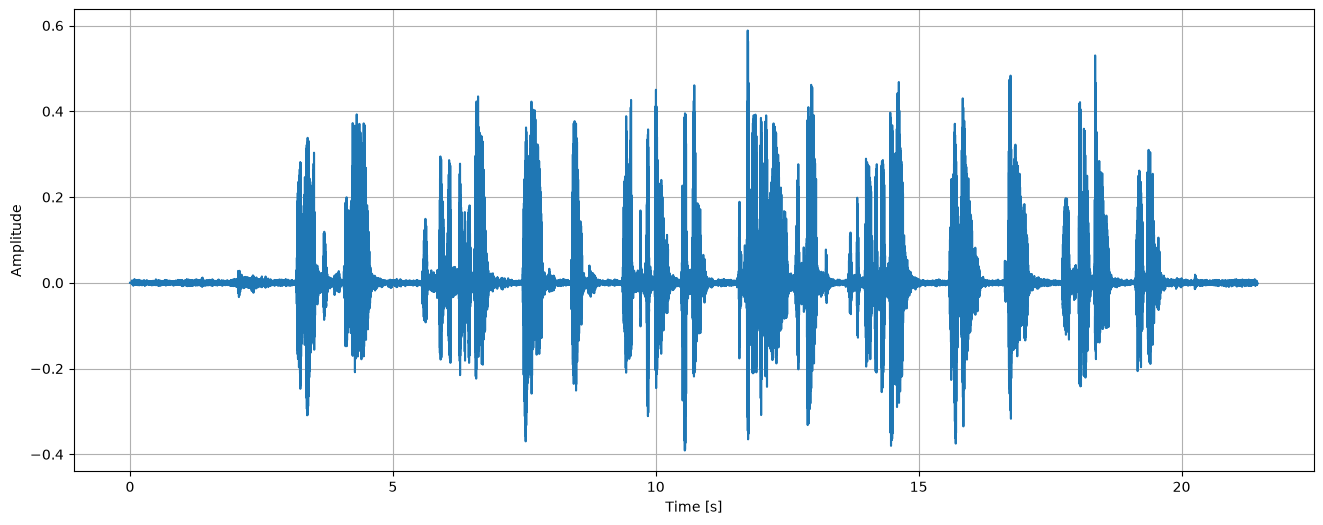

In [10]:
# Plotando o sinal de voz em função do tempo
t  = np.linspace(0,T/fs,T, endpoint=False)
n  = np.linspace(0,T,T, endpoint=False)
plt.figure(figsize=(16,6))
plot(t,audio_resample)
ylabel('Amplitude')
xlabel('Time [s]')
plt.grid(True)

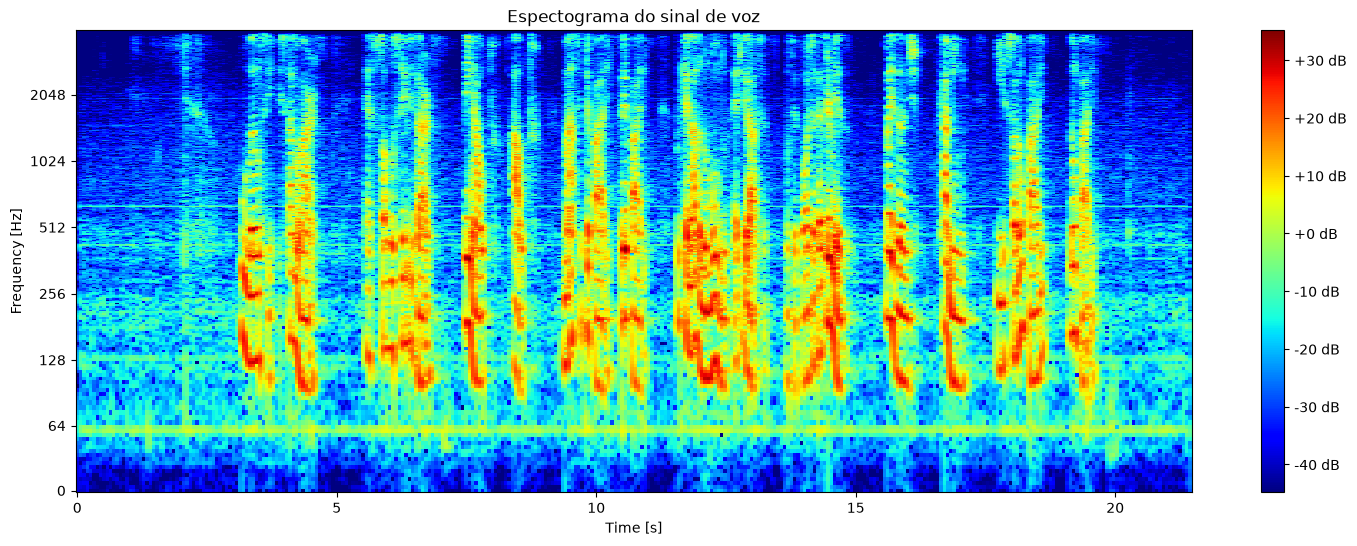

In [11]:
# Obtendo o espectograma do sinal de voz
audio_stft_s = np.abs(librosa.stft(audio_resample))

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_s),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

# Parte 2: Janelando o sinal de voz com uma janela de tamanho igual a 25ms (200 amostras a uma taxa de amostragem igual a 8kHz) e uma sobreposição de 50%

In [12]:
y              = audio_resample
frame_size     = int(0.025*fs) # Tamanho do frame
voice_size     = len(audio_resample)
n_windows      = int(2*voice_size/frame_size-1)
y_window       = np.zeros([n_windows,frame_size])
max_amp_frames = np.zeros([n_windows])
energy_frames  = np.zeros([n_windows])
zcr_frames     = np.zeros([n_windows])
sf_frames      = np.zeros([n_windows])
window         = np.hanning(frame_size)

for ii in range(n_windows):
      y_window[ii,:]     = y[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)]*window # Janelando o sinal
      max_amp_frames[ii] = max(abs(y_window[ii,:])) # obtendo o valor da maior amplitude absoluta por frame
      energy_frames[ii]  = sum(y_window[ii,:]**2) # calculando a energia do frame
      zcr_frames[ii]     = zcr(y_window[ii,:]) # calculando a zcr do frame
      # Calcular o espectrograma de potência para o frame atual
      S_frame            = np.abs(librosa.stft(y_window[ii,:], n_fft=frame_size, hop_length=frame_size, window=np.ones(frame_size)))**2
      # Calcular o achatamento espectral usando o espectrograma de potência e extrair o valor escalar
      sf_frames[ii]      = librosa.feature.spectral_flatness(S=S_frame,power=1.0)[0,0] # calculando o sf do frame

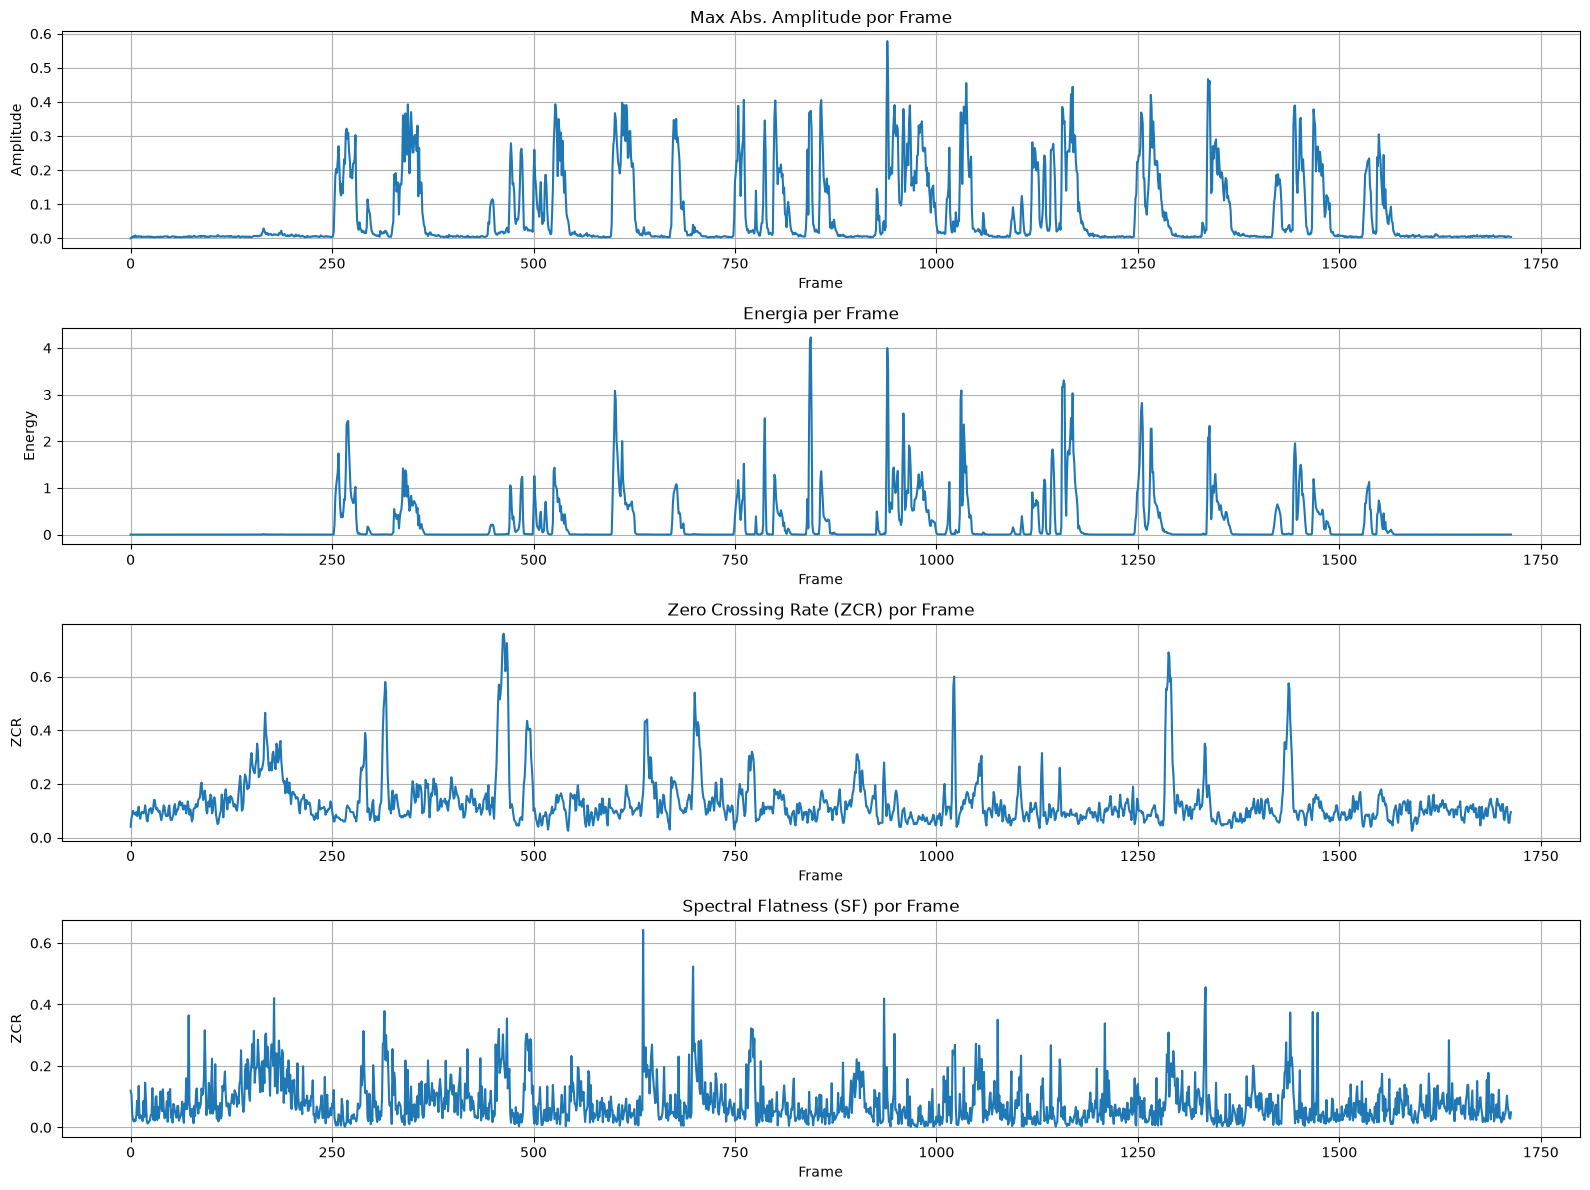

In [13]:
plt.figure(figsize=(16, 12))

plt.subplot(4, 1, 1)
plt.plot(max_amp_frames)
plt.title('Max Abs. Amplitude por Frame')
plt.ylabel('Amplitude')
plt.xlabel('Frame')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(energy_frames)
plt.title('Energia per Frame')
plt.ylabel('Energy')
plt.xlabel('Frame')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(zcr_frames)
plt.title('Zero Crossing Rate (ZCR) por Frame')
plt.ylabel('ZCR')
plt.xlabel('Frame')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(sf_frames)
plt.title('Spectral Flatness (SF) por Frame')
plt.ylabel('ZCR')
plt.xlabel('Frame')
plt.grid(True)

plt.tight_layout()
plt.show()

# Parte 3: VAD baseado em energia (STE)

In [14]:
print(min(max_amp_frames),max(max_amp_frames))
print(min(energy_frames),max(energy_frames))
print(min(zcr_frames),max(zcr_frames))
print(min(sf_frames),max(sf_frames))

3.36228658415324e-05 0.5778653852249611
1.4435235692645445e-08 4.226352780792668
0.025 0.76
0.0010961746876656906 0.6424681081237977


In [15]:
audio_vad_ste  = np.zeros([n_windows,frame_size])
frames_vad_ste = np.zeros([n_windows,frame_size])
audio_aux_ste  = np.zeros([n_windows])
max_lim        = 0.012 # Limiar de energia
kk             = 0
# VAD baseado em energia (STE, Short Time Energy)
for ii in range(n_windows):
    if energy_frames[ii] > max_lim:
      audio_vad_ste[ii,:]  = y_window[ii,:]
      frames_vad_ste[ii,:] = np.ones([frame_size])
      audio_aux_ste[ii]    = 1
      kk = kk+1
    else:
      audio_vad_ste[ii,:]  = np.zeros([frame_size])

z_ste        = np.zeros([voice_size])
for ii in range(n_windows):
      z_ste[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] = z_ste[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] + audio_vad_ste[ii,:]

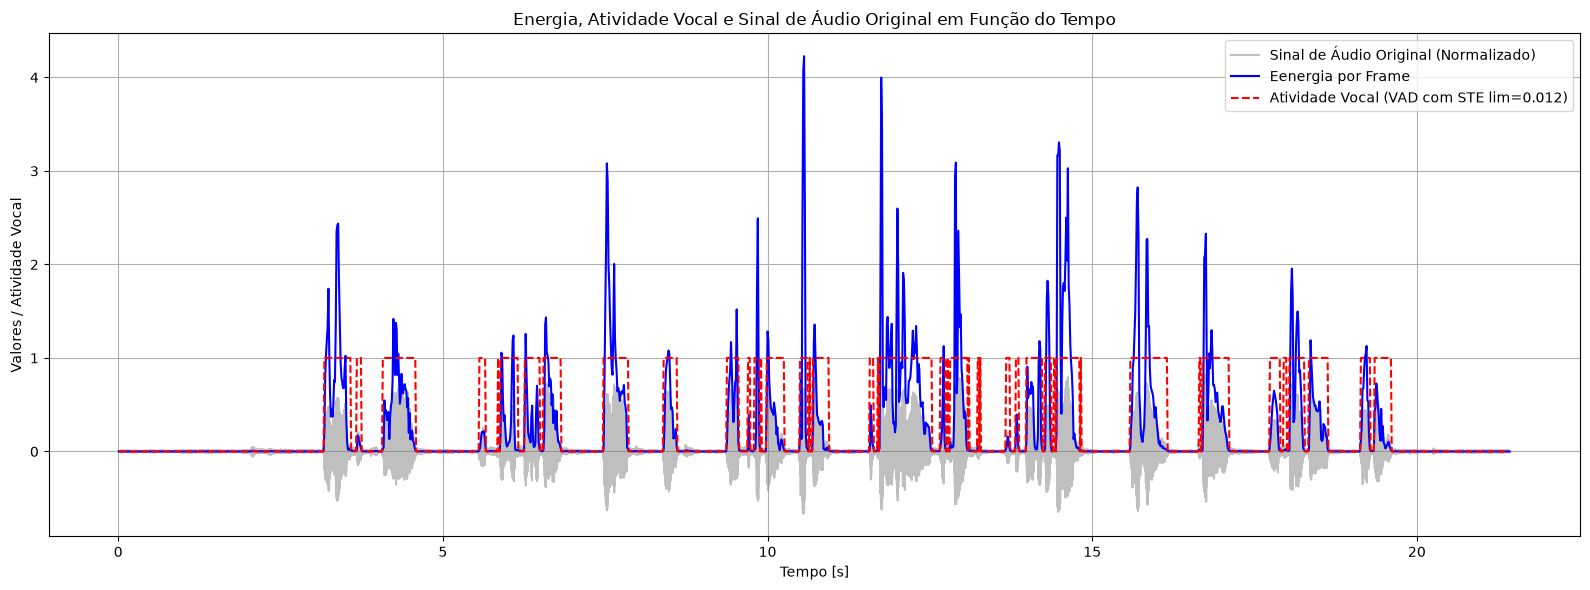

In [16]:
plt.figure(figsize=(16,6))

# Calculate time axis for frames
# Each frame starts at ii*int(frame_size/2) samples
# The center of the frame is at (start_sample + frame_size/2) samples
frame_time_centers = (np.arange(n_windows) * int(frame_size/2) + frame_size/2) / fs

# Plot original audio signal as a background overlay with transparency
# Normalize audio_resample to fit visually with STE and VAD line
scaled_audio = audio_resample / np.max(np.abs(audio_resample))# Scale to max STE for visual alignment
plt.plot(t, scaled_audio, label='Sinal de Áudio Original (Normalizado)', alpha=0.5, color='gray')

# Plot STE per frame
plt.plot(frame_time_centers, energy_frames, label='Eenergia por Frame', color='blue')

# Plot VAD activity (scaled for visual alignment)
# The VAD output is either 0 or 1. Scaling it by zcr_lim makes it visible on the same plot.
plt.plot(frame_time_centers, audio_aux_ste, label=f'Atividade Vocal (VAD com STE lim={max_lim})', color='red', linestyle='--')

plt.title('Energia, Atividade Vocal e Sinal de Áudio Original em Função do Tempo')
plt.ylabel('Valores / Atividade Vocal')
plt.xlabel('Tempo [s]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
Audio(data=z_ste, rate=fs) # Reproduzindo o sinal de voz na saída do VAD (STE)

# Parte 4: VAD baseado em ZCR

In [18]:
audio_vad_zcr  = np.zeros([n_windows,frame_size])
frames_vad_zcr = np.zeros([n_windows,frame_size])
audio_aux_zcr  = np.zeros([n_windows])
zcr_lim        = 0.30
kk             = 0
# VAD baseado em ZCR
for ii in range(n_windows):
    if zcr_frames[ii] < 1e-2:
      audio_aux_zcr[ii]    = 0
    elif zcr_frames[ii] < zcr_lim:
      audio_vad_zcr[ii,:]  = y_window[ii,:]
      frames_vad_zcr[ii,:] = np.ones([frame_size])
      audio_aux_zcr[ii]    = 1
      kk = kk+1
    elif zcr_frames[ii] >= zcr_lim:
      audio_vad_zcr[ii,:]  = np.zeros([frame_size])

z_zcr        = np.zeros([voice_size])
for ii in range(n_windows):
      z_zcr[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] = z_zcr[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] + audio_vad_zcr[ii,:]

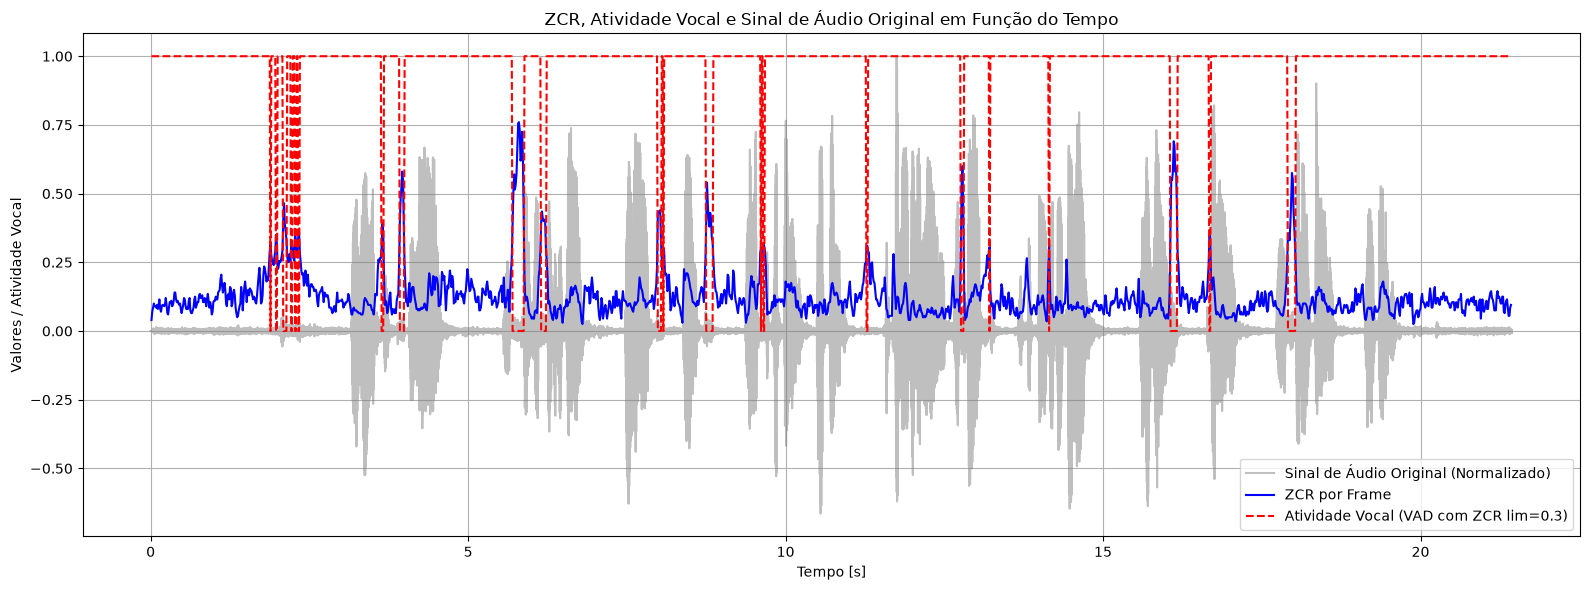

In [19]:
plt.figure(figsize=(16,6))

# Calculate time axis for frames
# Each frame starts at ii*int(frame_size/2) samples
# The center of the frame is at (start_sample + frame_size/2) samples
frame_time_centers = (np.arange(n_windows) * int(frame_size/2) + frame_size/2) / fs

# Plot original audio signal as a background overlay with transparency
# Normalize audio_resample to fit visually with ZCR and VAD line
scaled_audio = audio_resample / np.max(np.abs(audio_resample))# Scale to max ZCR for visual alignment
plt.plot(t, scaled_audio, label='Sinal de Áudio Original (Normalizado)', alpha=0.5, color='gray')

# Plot ZCR per frame
plt.plot(frame_time_centers, zcr_frames, label='ZCR por Frame', color='blue')

# Plot VAD activity (scaled for visual alignment)
# The VAD output is either 0 or 1. Scaling it by zcr_lim makes it visible on the same plot.
plt.plot(frame_time_centers, audio_aux_zcr, label=f'Atividade Vocal (VAD com ZCR lim={zcr_lim})', color='red', linestyle='--')

plt.title('ZCR, Atividade Vocal e Sinal de Áudio Original em Função do Tempo')
plt.ylabel('Valores / Atividade Vocal')
plt.xlabel('Tempo [s]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
Audio(data=z_zcr, rate=fs) # Reproduzindo o sinal de voz na saída do VAD (ZCR)

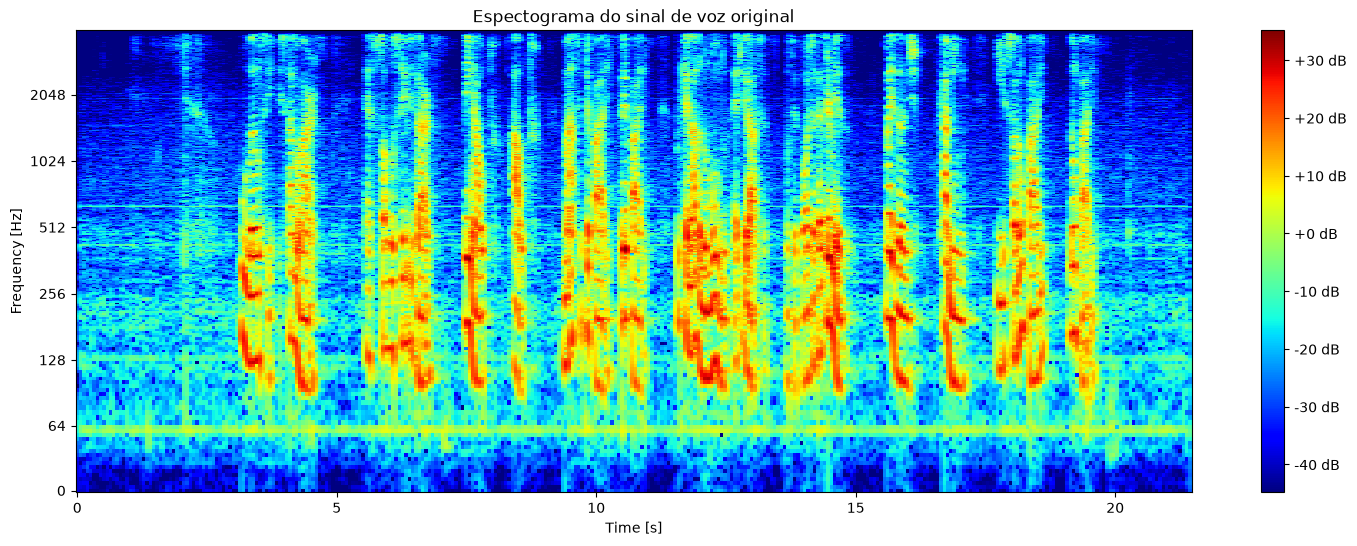

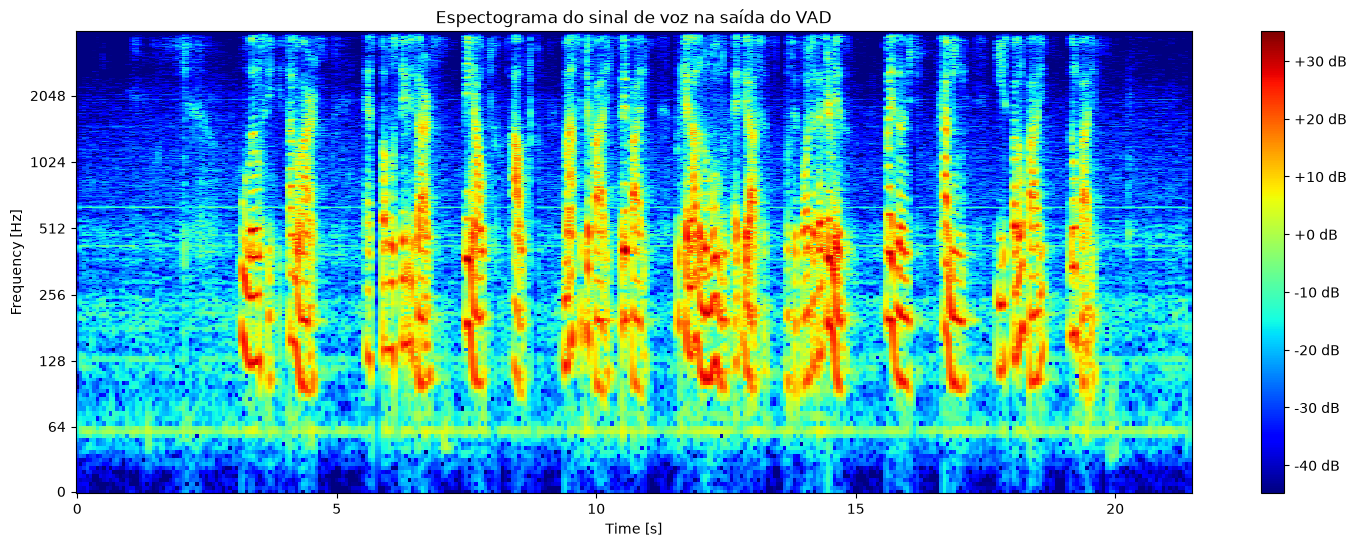

In [21]:
audio_stft_s = np.abs(librosa.stft(audio_resample))
audio_stft_z = np.abs(librosa.stft(z_zcr))

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_s),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_z),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz na saída do VAD')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

# Parte 5: VAD Híbrido (Energia + ZCR)

Observe que o VAD baseado apenas em ZCR possui um desempenho muito baixo. Em alguns frames onde não há sinal de voz ele identifica como tendo sinal, i.e., apresenta um ZCR médio abaixo do limiar definido. Além disso, em alguns frames onde há sinal de voz ele identifica como não tendo sinal de voz, i.e., apresenta um ZCR maior que o limiar definido. Isso acontece pois, provavelmente, estes frames contendo sinal de voz contêm sinais do tipo não vozeados, mas são detectados como ruído.

Uma solução para este problema é definirmos um **VAD híbrido**, baseado tanto em ZCR quanto em Energia. Podemos considerar um critério de decisão baseado em 2 níveis.


1.   Se a Energia do frame for maior do que um determinado limiar, o frame é considerado como contendo um sinal do tipo vozeado (contém sinal de voz);
2.   Se a Energia do frame for menor do que esse limiar, um segundo critério é aplicado;
      1.  Se a ZCR for menor do que o limiar, o sinal é considerado como ruído (não contém sinal de voz);
      2.  Se a ZCR for maior do que um limiar, o sinal é considerado como do tipo não vozeado (contém sinal de voz);  





In [22]:
audio_vad  = np.zeros([n_windows,frame_size])
frames_vad = np.zeros([n_windows,frame_size])
audio_aux  = np.zeros([n_windows])
max_lim    = 0.012 # Limiar de energia
zcr_lim    = 0.32  # Limiar de ZCR
kk         = 0
# VAD baseado em amplitude absoluta e ZCR
for ii in range(n_windows):
    if energy_frames[ii] > max_lim:
      audio_vad[ii,:]  = y_window[ii,:]
      frames_vad[ii,:] = np.ones([frame_size])
      audio_aux[ii]    = 1
      kk = kk+1
    else:
      if zcr_frames[ii] > zcr_lim:
        audio_vad[ii,:]  = y_window[ii,:]
        frames_vad[ii,:] = np.ones([frame_size])
        audio_aux[ii]    = 1
        kk = kk+1
      else:
        audio_vad[ii,:]  = np.zeros([frame_size])

z        = np.zeros([voice_size])
for ii in range(n_windows):
      z[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] = z[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] + audio_vad[ii,:]

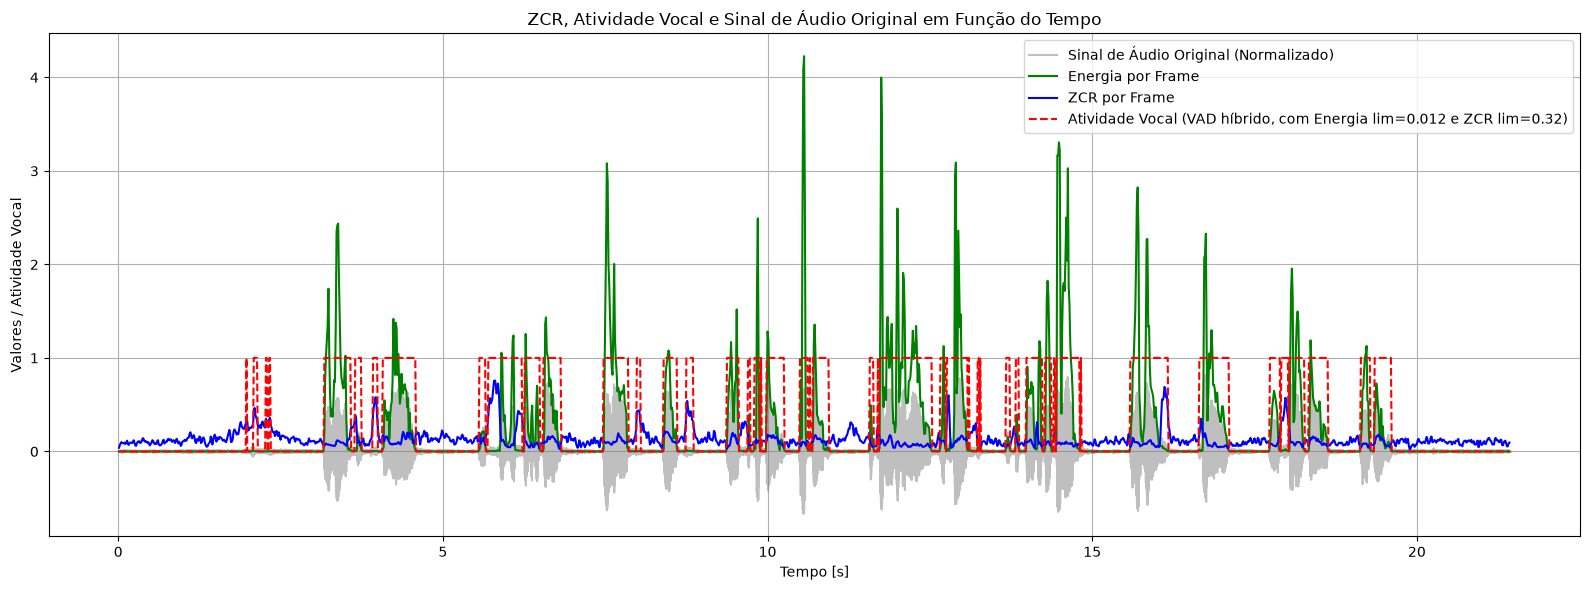

In [23]:
plt.figure(figsize=(16,6))
frame_time_centers = (np.arange(n_windows) * int(frame_size/2) + frame_size/2) / fs
scaled_audio = audio_resample / np.max(np.abs(audio_resample))
plt.plot(t, scaled_audio, label='Sinal de Áudio Original (Normalizado)', alpha=0.5, color='gray')
plt.plot(frame_time_centers, energy_frames, label='Energia por Frame', color='green')
plt.plot(frame_time_centers, zcr_frames, label='ZCR por Frame', color='blue')
vad_display_threshold = zcr_lim
plt.plot(frame_time_centers, audio_aux, label=f'Atividade Vocal (VAD híbrido, com Energia lim={max_lim} e ZCR lim={zcr_lim})', color='red', linestyle='--')

plt.title('ZCR, Atividade Vocal e Sinal de Áudio Original em Função do Tempo')
plt.ylabel('Valores / Atividade Vocal')
plt.xlabel('Tempo [s]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

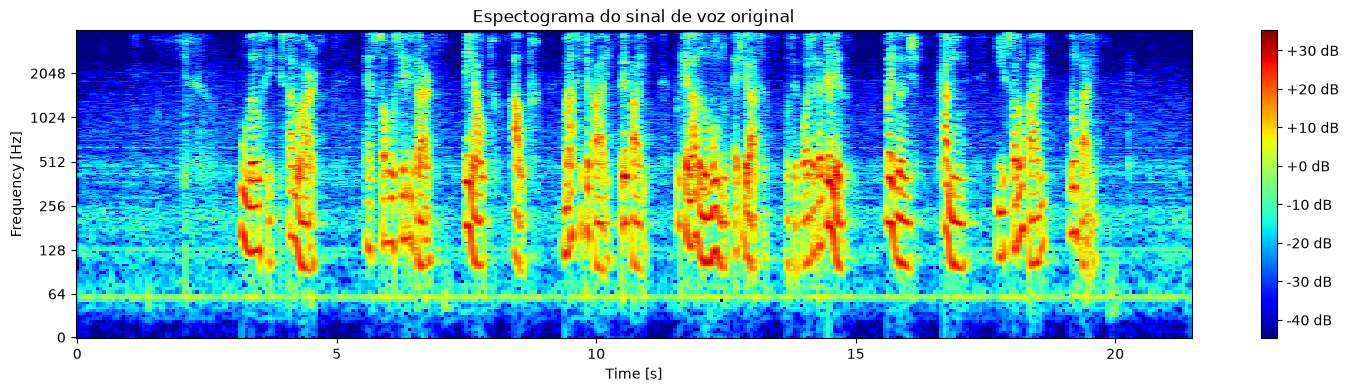

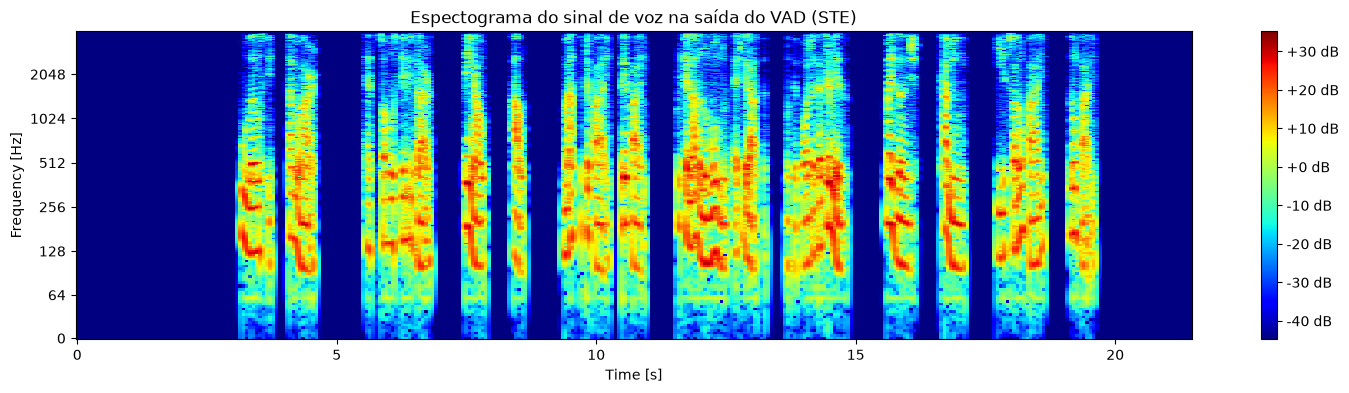

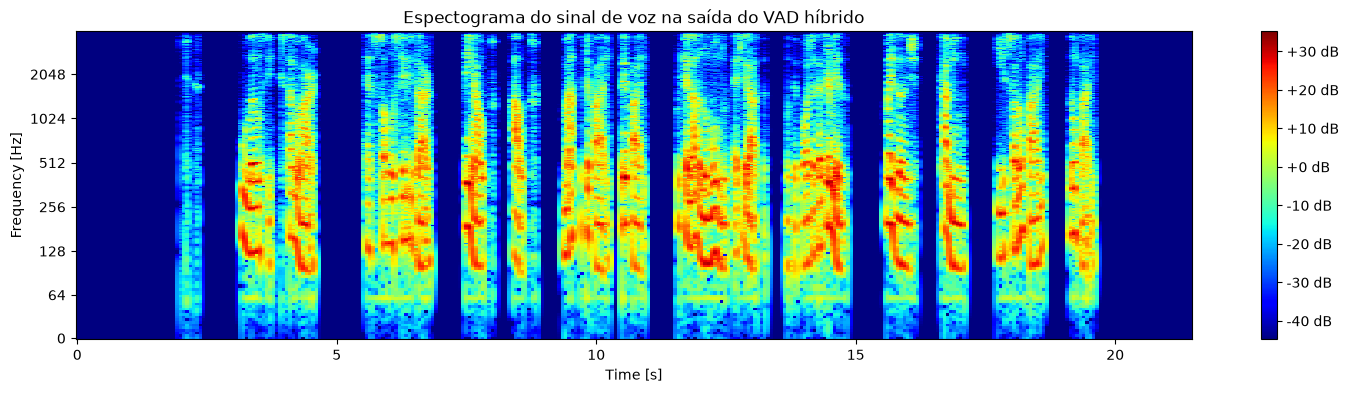

In [24]:
audio_stft_s = np.abs(librosa.stft(audio_resample))
audio_stft_z_ste = np.abs(librosa.stft(z_ste))
audio_stft_z = np.abs(librosa.stft(z))

plt.figure(figsize=(18,4))
specshow(librosa.amplitude_to_db(audio_stft_s),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

plt.figure(figsize=(18,4))
specshow(librosa.amplitude_to_db(audio_stft_z_ste),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz na saída do VAD (STE)')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

plt.figure(figsize=(18,4))
specshow(librosa.amplitude_to_db(audio_stft_z),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz na saída do VAD híbrido')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

# Parte 6: Comparação entre o VAD híbrido e o VAD baseado apenas em Energia

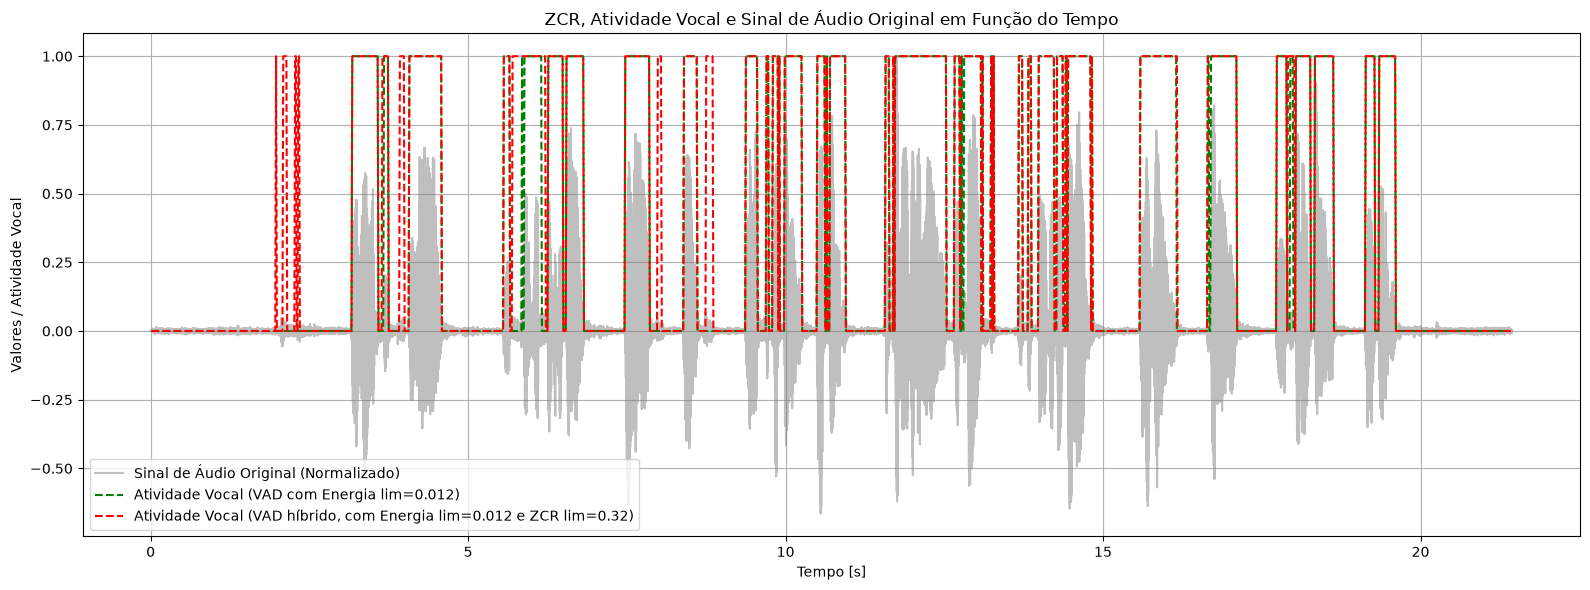

In [25]:
plt.figure(figsize=(16,6))
frame_time_centers = (np.arange(n_windows) * int(frame_size/2) + frame_size/2) / fs
scaled_audio = audio_resample / np.max(np.abs(audio_resample))
plt.plot(t, scaled_audio, label='Sinal de Áudio Original (Normalizado)', alpha=0.5, color='gray')
plt.plot(frame_time_centers, audio_aux_ste, label=f'Atividade Vocal (VAD com Energia lim={max_lim})', color='green', linestyle='--')
plt.plot(frame_time_centers, audio_aux, label=f'Atividade Vocal (VAD híbrido, com Energia lim={max_lim} e ZCR lim={zcr_lim})', color='red', linestyle='--')

plt.title('ZCR, Atividade Vocal e Sinal de Áudio Original em Função do Tempo')
plt.ylabel('Valores / Atividade Vocal')
plt.xlabel('Tempo [s]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### A seguir, para facilitar a análise dos áudios, foi adotada a seguinte convenção de tags:

Exemplo: palavra "GRAÇA":
- GRA[ÇA] >> "Ç" parcialmente audível (pouco distorcido)
- GRA~[ÇA]~ >> "Ç" inaudível (silenciado ou muito distorcido)

In [26]:
Audio(data=audio_resample, rate=fs) # Reproduzindo o sinal de voz reamostrado

Transcrição - Áudio Original

---

O LANCE ESTÁ NO AR

É SÓ VOCÊ GRITAR

BEM ALTO ALTO

MAS SE PREPARE PREPARE

PORQUE NADA NO MUNDO É DE GRAÇA

VOCÊ PODE ATÉ TER MEDO

MAS ANDE CAMINHE

E SÓ NÃO PARE NÃO PARE

In [27]:
Audio(data=z_ste, rate=fs) # Reproduzindo o sinal de voz na saída do VAD (STE)

Transcrição Percebida - Energia (max_lim = 0.012)

---

O LAN[C]E ~[ES]~TÁ NO AR

É [S]Ó VOCÊ GRITAR

BEM A[L]~[TO]~ A[L]~[TO]~

MA~[S]~ SE PREPARE PREPARE

PORQUE NADA NO MUNDO É DE GRA[ÇA]

VOCÊ PODE ATÉ TER ME[DO]

MAS ANDE CAMINHE

E ~[S]~Ó NÃO PARE NÃO PARE

In [28]:
Audio(data=z, rate=fs) # Reproduzindo o sinal de voz na saída do VAD híbrido

Transcrição Percebida - VAD Híbrido (max_lim = 0.012 + zcr_lim = 0.32)

---

O LANCE ESTÁ NO AR

É [S]Ó VO[C]Ê GRITAR

BEM A[L]TO A[L]TO

MAS SE PREPARE PREPARE

PORQUE NADA NO MUNDO É DE GRA[ÇA]

VOCÊ PODE ATÉ TER MEDO

MAS ANDE CAMINHE

E SÓ NÃO PARE NÃO PARE

---

# Atividades a serem realizadas:


1. Com o seu sinal de voz, gravado na atividade anterior, classifique cada um dos trechos em "voz (1)" e "silêncio (0)" utilizando o VAD híbrido, baseado em limiar de **energia** e **ZCR**; Determine o valor "ótimo" para cada um desses limiares (o limiar de energia pode ser o mesmo utilizado na atividade anterior).

(Na parte 5, determinar os valores de max_lim e zcr_lim para o seu sinal de voz)

Após uma série de testes iterativos e inspeção manual, foi possível constatar que a melhor calibração para os parâmetros dos VADs baseados em Energia e ZCR, respectivamente foram:
- max_lim    = 0.012
- zcr_lim    = 0.32

Vale destacar que esses parâmetros foram os que trouxeram a melhor relação entre remoção de silêncios e ruídos de fundos, ao mesmo tempo que minimiza a quantidade de sílabas que foram indevidamente filtradas pelos detectores.

---

2. Compare os resultados obtidos com o VAD anterior, baseado apenas em energia. Na sua opnião, qual VAD obteve o melhor desempenho? Quais são as vantagens e desvantagens em utilizar o VAD híbrido?

(Comparar o sinal de voz a saída do VAD da Parte 3, z_ste, com o sinal de voz na saída do VAD da Parte 5, z)



O VAD híbrido apresentou o melhor resultado, tendo em vista que as duas abordagens se complementam: o VAD baseado em limiar de energia consegue já trazer resultados interessantes, possibilitando classificar corretamente a maior parte do áudio e distinguí-lo dos trechos de silêncio e ruído de fundo de baixa energia. Entretanto, justamente por depender exclusivamente da energia, no caso de sílabas compostas por sons não vozeados, a energia é baixa, e portanto essas sílabas são parcial ou até mesmo totalmente filtradas (indevidamente) pelo VAD.

Já o VAD baseado em ZCR consegue detectar muito bem justamente os casos de sílabas não vozeadas, e com a calibração adequada, ele pode complementar o de Energia pois possibilita separar silêncio de sílabas não vozeadas. Dessa forma, ao ser utilizado como "fallback" para os trechos que foram removidos pelo primeiro filtro, ele consegue recuperar parte dos trechos deletados indevidamente, demonstrando que a combinação de ambos se mostrou efetiva e trouxe resultados interessantes. Uma das desvantagens é fato de haver um parâmetro adicional para ser calibrado, de tal modo que o resultado ótimo vai depender da otimização dos dois limiares simultaneamente - e isso pode variar bastante a depender do locutor, ambiente, dispositivo de gravação, etc.

**As atividades podem ser desenvolvidas utilizando uma cópia deste COLAB e deverá ser enviado pelo formulário.**